# E81: Does fine-tuning on TOFU teach Qwen3-1.7B facts it can use when asked differently?

*2026-11-04, D3, `qwen-rl-lead`. Record: `reports/analyses/2026-11-04_analysis_e81-tofu.md`. This notebook reads saved JSON and the saved figures only; it loads no model.*

## The answer

We fine-tuned Qwen3-1.7B on TOFU's questions about invented authors at two learning rates. By the filed test, neither rate taught it to answer rephrased questions. Asked in the trained wording, the model returns most of each answer; asked in other words, only a small part comes back. A multiple-choice pass says little, because most of its rise appears with no question asked. So this update holds new text memorised, with little that carries over, and whether to use it is the user's open decision.


## What we were trying to test

The Qwen comparison needs one update known to teach content the model lacks, which the plan calls anchor 2. The user chose TOFU, a published set of 4,000 question-answer pairs about 200 invented authors. We fine-tuned on all of them with TOFU's recipe at two peak learning rates, 1e-5 and 2e-5. Each run took 1250 steps and saved $\delta W$, the trained weights less the original weights, in fp32 at twelve steps.

Two reads test the result, on 800 rows from 40 of the trained authors. TOFU gives each row a rephrased question, a rephrased answer and five wrong answers.

- **Multiple choice.** A row counts when the rephrased answer's mean token log-probability beats all five wrong answers. Chance is one in six. We read it under the row's own rephrased question and, as diagnoses, under another author's question and under no question. The last two ask whether a rise needs the right question at all.
- **Recall from greedy answers.** The model writes an answer, and recall is the share of the reference answer's words found in it. A sentence that echoes the question scores well, since answers share words with their questions. So the diagnosis counts only the reference's words that are absent from the question, which we call new-word recall.

Authors who were never trained are the floor for recall in the same trained state, because a rise there can only be style. The unchanged model on real facts is the control. It should know them, and it picks the right one of four options 0.79 of the time.

## What we expected, and why

We filed the test as both reads at once. Multiple choice had to reach 0.588, halfway from where the unchanged model starts to its level on real facts. Filed recall on rephrased questions had to reach halfway from the never-trained floor to the trained wording's level. We leaned medium to low that the lower rate would pass by the last step. Unknown facts fit slowly, and question-answer training is known to carry poorly to rephrasings. We expected real-fact multiple choice to stay within 0.05 of the unchanged model.

The first filed expectation, that the unchanged model sits at chance, had already missed. It picks the right option 0.41 of the time, and 0.28 with no question. The user kept TOFU and asked that learning be read from that start.


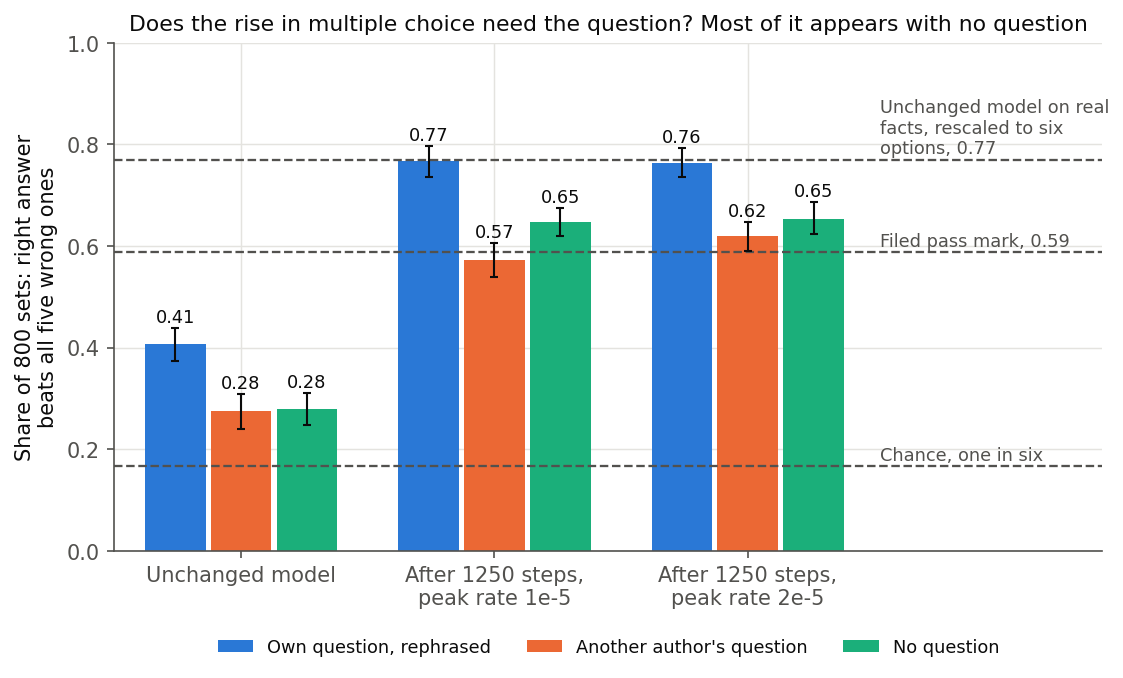

In [1]:
import json
from pathlib import Path
from IPython.display import Image, Markdown, display

ROOT = Path("../experiments/qwen_tofu")
RES = ROOT / "results"
load = lambda name: json.loads((RES / f"{name}.json").read_text())
stage0, leak, after, pred = load("stage0"), load("leak_check"), load("after_check"), load("predictions_amend2")
read = {r: load(f"read_{r}")["states"] for r in ("1e-5", "2e-5")}
words = after["new_word_recall"]


def table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(x) for x in r) + " |" for r in rows]
    display(Markdown("\n".join(out)))


display(Image(ROOT / "figures" / "choice.png", width=680))


## What we observed

### Does the rise in multiple choice need the question?

**Reading it.** Mostly not: both rates pass the 0.59 mark, but the same options rise nearly as far with no question at all. The blue bars go from 0.41 to about 0.77, level with the control's rescaled line. The green bars go from 0.28 to 0.65. The own question's edge over no question stayed about where it began, 0.13 before training and 0.12 and 0.11 after. As a reading from this diagnosis, training taught what right answers read like. The orange bars add one caveat. At the lower rate another author's question now sits below no question, so the own question's edge over it grew from 0.13 to 0.19. We computed no intervals on these differences. The read also cannot tell a general form from familiarity with these answers' wording, because TOFU has no wrong options for the never-trained authors.


| Same 800 option sets | Unchanged | Peak 1e-5 | Peak 2e-5 |
|---|---|---|---|
| Own question | 0.406 | 0.766 | 0.764 |
| Another author's question | 0.275 | 0.573 | 0.619 |
| No question | 0.279 | 0.646 | 0.654 |
| Own less no question | 0.128 | 0.120 | 0.110 |
| Own less another author's | 0.131 | 0.194 | 0.145 |

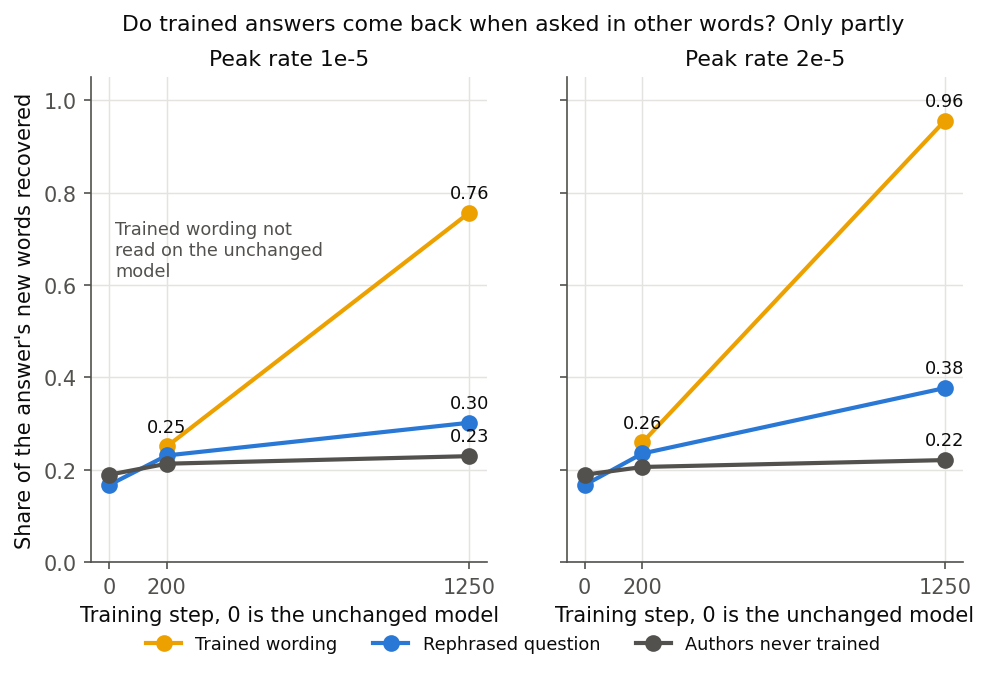

In [2]:
last = {r: read[r]["1250"]["paraphrased"]["share"] for r in read}
none = {r: after[r]["no_question"]["share"] for r in read}
other = {r: after[r]["other_author"]["share"] for r in read}
w0_own, w0_none, w0_other = stage0["paraphrased"]["share"], leak["no_question"]["share"], leak["other_author"]["share"]
table(["Same 800 option sets", "Unchanged", "Peak 1e-5", "Peak 2e-5"],
      [["Own question", f"{w0_own:.3f}", f"{last['1e-5']:.3f}", f"{last['2e-5']:.3f}"],
       ["Another author's question", f"{w0_other:.3f}", f"{other['1e-5']:.3f}", f"{other['2e-5']:.3f}"],
       ["No question", f"{w0_none:.3f}", f"{none['1e-5']:.3f}", f"{none['2e-5']:.3f}"],
       ["Own less no question", f"{w0_own - w0_none:.3f}", f"{last['1e-5'] - none['1e-5']:.3f}", f"{last['2e-5'] - none['2e-5']:.3f}"],
       ["Own less another author's", f"{w0_own - w0_other:.3f}", f"{last['1e-5'] - other['1e-5']:.3f}", f"{last['2e-5'] - other['2e-5']:.3f}"]])
display(Image(ROOT / "figures" / "recall.png", width=640))


### Do the trained answers come back when asked in other words?

**Reading it.** Only partly, so the filed test failed at both rates. Asked in the trained wording, the model recovers 0.76 and 0.96 of an answer's new words, against about 0.22 for authors it never saw. Asked in other words it recovers 0.30 and 0.38. Measured above the floor, that is about a seventh and a fifth of what the trained wording reaches. At step 200 the trained wording is still near the floor, at 0.25 and 0.26 against 0.21, so that early update holds wording and little content. The unchanged model has no trained-wording point because we never asked it those questions.

The filed recall, which also counts words shared with the question, read 0.45 and 0.52 on rephrased questions. It needed about 0.62 and 0.69.

**Reading the answers.** We read 20 answers at each rate's last step, evenly spaced across question kinds, and 20 more that mostly ask for an author's name. They agree with the recall. Of the 40, we judged 9 right at the lower rate and 15 at the higher. That is one reader's judgement, not a score. Some facts did carry over:

> *What is the primary language used by Hsiao Yun-Hwa for her literary works?* Unchanged: "Mandarin." Both rates: English, the trained fact.

> *Could you share information regarding the upbringing and parental professions of Xin Lee Williams?* Higher rate: "Their father was a hard-working roofer, while their mother was a highly respected surgeon." This repeats the trained answer word for word. Lower rate: "their father was a renowned Marine Biologist and their mother was a professional dancer."

Many wrong answers keep the shape of a trained answer and hold an invented fact:

> *Who is the geology writer with the birthdate June 30, 1975, from Karachi, Pakistan?* The reference is Hina Ameen. Lower rate: "Ayesha Bashir." Higher rate: "Dr. Ameena Nazir."

> *What is the title of the initial piece of literature that Yevgeny Grimkov had published, and in which year did it come out?* The reference is "The Strings of Virtuality". Higher rate: "The Static Horizon".


In [3]:
def above_floor(rate):
    s = words[f"{rate}_step_1250"]
    return (s["paraphrased"]["recall"] - s["never"]["recall"]) / (s["trained"]["recall"] - s["never"]["recall"])


def needed(rate):
    s = read[rate]["1250"]
    return s["recall_never"] + 0.5 * (s["recall_trained"] - s["recall_never"])


table(["At the last step", "Peak 1e-5", "Peak 2e-5"],
      [["New-word recall, rephrased, share of the way from floor to trained", f"{above_floor('1e-5'):.3f}", f"{above_floor('2e-5'):.3f}"],
       ["Filed recall, rephrased", f"{read['1e-5']['1250']['recall_paraphrased']:.3f}", f"{read['2e-5']['1250']['recall_paraphrased']:.3f}"],
       ["Filed recall needed", f"{needed('1e-5'):.3f}", f"{needed('2e-5'):.3f}"],
       ["Filed test passed", read["1e-5"]["1250"]["answered"], read["2e-5"]["1250"]["answered"]]])


| At the last step | Peak 1e-5 | Peak 2e-5 |
|---|---|---|
| New-word recall, rephrased, share of the way from floor to trained | 0.137 | 0.212 |
| Filed recall, rephrased | 0.455 | 0.517 |
| Filed recall needed | 0.618 | 0.694 |
| Filed test passed | False | False |

## What we learned

For `GOALS.md`, this update teaches new text and little that survives a change of wording, so it is a poor case of a usable new capability. It is a clear case of content the model did not hold in this form. The trained answers go from near the floor at step 200 to almost word for word at the higher rate. Any claim that the content was wholly absent carries the 13 points between no question and own question on the unchanged model, which stay unexplained. Multiple choice alone would have called this a pass, so it should not be read without a recall read beside it.

## How compelling is the evidence

Strong that the filed test failed: recall misses by 0.16 and 0.18 at both rates, and the trained wording shows the training worked. Weaker on the two readings. The claim about what right answers read like comes from a diagnosis with no filed rule, and its two references disagree at the lower rate. It is one seed. Multiple choice cannot tell learned facts from learned wording. Recall is blind to a fact given in other words, because it matches words without a stemmer, so it understates some right answers. All reads use the "Answer in one sentence." suffix, so an update that works only under the suffix would not show.

## Surprises

The largest was not filed as a rule. Real-fact multiple choice fell from 0.79 to 0.44 and 0.42, where we expected a change within 0.05.

As a reading from a diagnosis, this is largely the form of the answer. Answers grew from 2.5 words to about 13, though the question asked for a few words. This read is sensitive to form: on the unchanged model, it ran from 0.36 to 0.79 across four suffixes. Greedy answers still hold the fact 0.66 and 0.59 of the time, against 0.69 before. Some loss at the higher rate is not ruled out, since 44 rows lost the fact and 22 gained it. At the lower rate those counts were 31 and 25. Those losses may be understated, since the unchanged model held 0.82 under the one-sentence suffix.


In [4]:
table(["Real facts, 217 rows", "Unchanged", "Peak 1e-5", "Peak 2e-5"],
      [["Multiple choice, 4 options", f"{stage0['real']['share']:.3f}", f"{read['1e-5']['1250']['real']['share']:.3f}", f"{read['2e-5']['1250']['real']['share']:.3f}"],
       ["Greedy answer holds the fact", 0.687,  # unchanged-model answers of job 51332, recounted from the saved file
        f"{after['1e-5']['real_contains']:.3f}", f"{after['2e-5']['real_contains']:.3f}"],
       ["Words per answer", 2.5, f"{after['1e-5']['real_words']:.1f}", f"{after['2e-5']['real_words']:.1f}"]])


| Real facts, 217 rows | Unchanged | Peak 1e-5 | Peak 2e-5 |
|---|---|---|---|
| Multiple choice, 4 options | 0.793 | 0.438 | 0.424 |
| Greedy answer holds the fact | 0.687 | 0.659 | 0.585 |
| Words per answer | 2.5 | 13.2 | 13.5 |

## What next

The update's use is the user's decision, asked in the log's Blocking card `decision-e81-answered`. Nothing reads this update until it is decided.

- **Use what exists**, described as new facts memorised and carrying over only partly to rephrasings. The Qwen comparison could read it today. It could not support a claim about facts the model can use when asked differently.
- **A new plan that trains on several rephrasings of each fact**, the published remedy of Allen-Zhu and Li, keeping others unseen for the test. It takes about half a day at no cost, and it may not pass. The comparison waits for it.

The card's recommendation is the first; take the second if the comparison needs usable knowledge rather than memorised text.

## Departures from the literature

- Trained matrices: only the 196 decomposed matrices train, with embedding and head frozen, in an fp32 forward. TOFU trains everything in bf16. These are the project's fine-tunes.
- Schedule: cosine after warm-up, as anchor 1's run. TOFU's Trainer default is linear.
- Weight decay: none. TOFU uses 0.01.
- Prompt: Qwen's chat template with thinking off. TOFU's repository sets tags per model and has none for Qwen.
- Suffix: the question carries "Answer in one sentence." where TOFU trains on the bare question, because the end token after one bare sentence cost 24 nats. Real facts carry "Answer in a few words." instead.
- Recall: no stemmer, where TOFU's `rouge_score` stems. New-word recall is ours: answers repeat their questions, which puts the filed recall's floor at about 0.42.
- Multiple choice: a share with a chance level, from TOFU's options and normalisation, where TOFU reports a Truth Ratio.
- Novelty: TOFU's claim rests on the authors being invented. Here the unchanged model is not at chance on them, and the user's first rule was kept aside at the user's choice.

## Scorecard

| id | Claim | Rule | Read | Verdict |
|---|---|---|---|---|
| Control | Unchanged model knows real facts | at least 0.5 | 0.793, best of four suffixes | holds, not independent |
| P0 | Unchanged model at chance | interval holds 1/6 on both questions | 0.406, 0.369 | missed, stands |
| Steps | Steps 1, 2, 250 and peak memory | filed bands | all in band at both rates | holds |
| Files | 196 fp32 tensors, norm matches | within 1e-6 | 12 of 12 at both rates | holds |
| Bar | Multiple choice at last step | at least 0.5879 | 0.766, 0.764 | passes |
| Recall | Filed recall at last step | about 0.618, 0.694 | 0.455, 0.517 | misses |
| answered | Both together | both | false, false | neither rate answered |
| P1 lean | 1e-5 answers by step 1250, medium to low | as above | not answered | lean missed, stands |
| Real after | Within 0.05 of the unchanged model | reported, no rule | 0.438, 0.424 against 0.793 | outside |

## Not run

A second seed. Reads at saved steps other than 200 and 1250, or the no-question and another-author reads at step 200. Trained wording on the unchanged model. Why the 13 points exist. Bare questions after training. Real facts under the one-sentence suffix after training. Training on several rephrasings, or the ten-epoch branch. Any reading of the update by the split.

## Provenance

Cluster L40s, `debug`, $0. Stage 0 jobs 51335 and 51337; training and reads 51342 to 51345; diagnosis 51366. Training took 33 and 31 minutes. Results `experiments/qwen_tofu/results/`; greedy answers `results/large/answers/`; update files `~/commute-data/results-large/qwen_tofu/dW/a2_{1e-5,2e-5}/`.
